In [377]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [378]:
df=pd.read_csv('cleaned_data_with_outliers.csv')

In [379]:
df.isnull().sum()

user_id                        0
charger_id                     0
charger_company_code           0
charging_location              0
charger_type_code              0
start_day                      0
start_time                     0
end_day                        0
end_time                       0
start_datetime                 0
end_datetime                   0
duration_minutes               0
demand_value                   0
start_hour                     0
demand_level                   0
calculated_duration_minutes    0
charger_speed_category         0
time_taken_for_charging        0
charging_days                  0
charging_time                  0
charging_hours                 0
charging_minutes               0
charger_company_name           0
dtype: int64

In [380]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72826 entries, 0 to 72825
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   user_id                      72826 non-null  int64  
 1   charger_id                   72826 non-null  int64  
 2   charger_company_code         72826 non-null  int64  
 3   charging_location            72826 non-null  object 
 4   charger_type_code            72826 non-null  int64  
 5   start_day                    72826 non-null  object 
 6   start_time                   72826 non-null  object 
 7   end_day                      72826 non-null  object 
 8   end_time                     72826 non-null  object 
 9   start_datetime               72826 non-null  object 
 10  end_datetime                 72826 non-null  object 
 11  duration_minutes             72826 non-null  int64  
 12  demand_value                 72826 non-null  float64
 13  start_hour      

In [381]:
for i in df.select_dtypes(include=['int64', 'float64']).columns:
    print(i)

user_id
charger_id
charger_company_code
charger_type_code
duration_minutes
demand_value
start_hour
calculated_duration_minutes
charging_days
charging_hours
charging_minutes


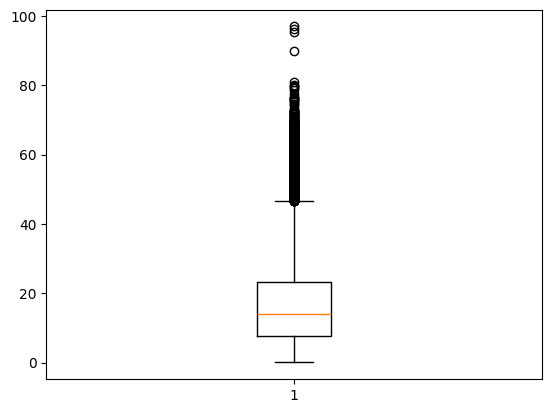

In [382]:
plt.boxplot(df['demand_value'])
plt.show()

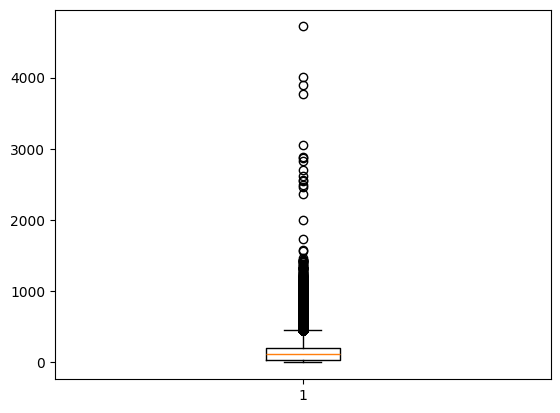

In [383]:
plt.boxplot(df['calculated_duration_minutes'])
plt.show()

In [384]:
columns = [
    "demand_value",
    "calculated_duration_minutes"
]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

In [385]:
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outlier_mask = (df[col] < lower) | (df[col] > upper)

print(f"\nColumn: {col}")
print("Lower bound:", round(lower, 2))
print("Upper bound:", round(upper, 2))
print("Outlier count:", outlier_mask.sum())
print("Outlier percentage:", round(outlier_mask.mean() * 100, 2), "%")


Column: calculated_duration_minutes
Lower bound: -204.51
Upper bound: 449.07
Outlier count: 4201
Outlier percentage: 5.77 %


In [386]:
df["duration_difference"] = (
    df["calculated_duration_minutes"]
    - df["duration_minutes"]
)

display(
    df[
        [
            "duration_minutes",
            "calculated_duration_minutes",
            "duration_difference"
        ]
    ].head(10)
)

df['duration_difference']=df['duration_difference'].abs()

df['duration_difference'].head(5)

,duration_minutes,calculated_duration_minutes,duration_difference
0,185,185.183333,0.183333
1,90,89.983333,-0.016667
2,60,59.983333,-0.016667
3,344,343.850000,-0.150000
4,300,299.983333,-0.016667
5,70,69.983333,-0.016667
6,60,59.983333,-0.016667
7,494,494.033333,0.033333
8,60,59.983333,-0.016667
9,112,112.266667,0.266667


0    0.183333
1    0.016667
2    0.016667
3    0.150000
4    0.016667
Name: duration_difference, dtype: float64

In [387]:
df["start_datetime"] = pd.to_datetime(
    df["start_datetime"], errors="coerce"
)

df["end_datetime"] = pd.to_datetime(
    df["end_datetime"], errors="coerce"
)

df["verified_duration_minutes"] = (
    df["end_datetime"] - df["start_datetime"]
).dt.total_seconds() / 60

df["original_difference"] = (
    df["verified_duration_minutes"]
    - df["duration_minutes"]
)

df["calculation_difference"] = (
    df["verified_duration_minutes"]
    - df["calculated_duration_minutes"]
)

display(
    df[
        [
            "start_datetime",
            "end_datetime",
            "duration_minutes",
            "calculated_duration_minutes",
            "verified_duration_minutes",
            "original_difference",
            "calculation_difference"
        ]
    ].loc[[68945, 18795, 13420, 72400, 8022]]
)

,start_datetime,end_datetime,duration_minutes,calculated_duration_minutes,verified_duration_minutes,original_difference,calculation_difference
68945,2022-05-14 13:59:33,2022-05-17 20:36:35,397,4717.033333,4717.033333,4320.033333,0.000000e+00
18795,2021-10-01 18:31:08,2021-10-04 13:17:25,101,4006.283333,4006.283333,3905.283333,4.547474e-13
13420,2022-03-30 22:04:34,2022-04-02 15:00:15,157,3895.683333,3895.683333,3738.683333,4.547474e-13
72400,2022-03-24 22:08:20,2022-03-27 13:01:11,893,3772.850000,3772.850000,2879.850000,0.000000e+00
8022,2022-03-05 09:09:11,2022-03-07 12:09:13,132,3060.033333,3060.033333,2928.033333,0.000000e+00


In [388]:
difference = (
    df["verified_duration_minutes"]
    - df["duration_minutes"]
).abs()

print("Total records:", len(df))
print("Differences greater than 1 minute:", (difference > 1).sum())
print("Differences greater than 60 minutes:", (difference > 60).sum())
print("Differences greater than 24 hours:", (difference > 1440).sum())

Total records: 72826
Differences greater than 1 minute: 4263
Differences greater than 60 minutes: 614
Differences greater than 24 hours: 15


In [389]:
df["verified_duration_minutes"] = (
    pd.to_datetime(df["end_datetime"], errors="coerce")
    - pd.to_datetime(df["start_datetime"], errors="coerce")
).dt.total_seconds() / 60

df["duration_difference"] = (
    df["verified_duration_minutes"]
    - df["duration_minutes"]
)

display(
    df.loc[
        df["duration_difference"].abs() > 1440,
        [
            "start_datetime",
            "end_datetime",
            "duration_minutes",
            "calculated_duration_minutes",
            "verified_duration_minutes",
            "duration_difference"
        ]
    ].sort_values(
        "duration_difference",
        key=abs,
        ascending=False
    )
)

,start_datetime,end_datetime,duration_minutes,calculated_duration_minutes,verified_duration_minutes,duration_difference
68945,2022-05-14 13:59:33,2022-05-17 20:36:35,397,4717.033333,4717.033333,4320.033333
18795,2021-10-01 18:31:08,2021-10-04 13:17:25,101,4006.283333,4006.283333,3905.283333
13420,2022-03-30 22:04:34,2022-04-02 15:00:15,157,3895.683333,3895.683333,3738.683333
8022,2022-03-05 09:09:11,2022-03-07 12:09:13,132,3060.033333,3060.033333,2928.033333
72400,2022-03-24 22:08:20,2022-03-27 13:01:11,893,3772.850000,3772.850000,2879.850000
72169,2021-10-25 08:57:16,2021-10-27 09:00:02,3,2882.766667,2882.766667,2879.766667
4911,2021-10-23 23:54:59,2021-10-25 23:50:59,167,2876.000000,2876.000000,2709.000000
21530,2022-01-21 23:14:22,2022-01-23 22:28:59,214,2834.616667,2834.616667,2620.616667
21540,2021-11-13 23:05:57,2021-11-15 20:08:43,177,2702.766667,2702.766667,2525.766667
4862,2022-03-08 18:24:41,2022-03-10 12:49:59,229,2545.300000,2545.300000,2316.300000


In [390]:
df["duration_difference"] = (
    df["verified_duration_minutes"]
    - df["duration_minutes"]
)

major_diff = df[
    df["duration_difference"].abs() > 60
]

print("Records with differences over 60 minutes:", len(major_diff))

display(
    major_diff[
        [
            "duration_minutes",
            "calculated_duration_minutes",
            "demand_value",
            "charger_type_code",
            "charger_speed_category",
            "charger_company_name",
            "charging_location"
        ]
    ].head(20)
)

Records with differences over 60 minutes: 614


,duration_minutes,calculated_duration_minutes,demand_value,charger_type_code,charger_speed_category,charger_company_name,charging_location
15,4,120.000000,12.42,0,SlowCharger,Company B,hotel
66,0,75.000000,8.34,0,SlowCharger,Company B,hotel
246,0,174.550000,17.32,0,SlowCharger,Company B,hotel
348,0,233.083333,16.87,0,SlowCharger,Company B,hotel
349,0,192.300000,19.69,0,SlowCharger,Company B,hotel
361,0,76.233333,8.59,0,SlowCharger,Company B,hotel
364,0,374.216667,39.01,0,SlowCharger,Company B,hotel
378,0,188.500000,17.81,0,SlowCharger,Company B,hotel
2153,112,617.733333,11.80,0,SlowCharger,Company B,apartment
2160,165,608.750000,8.70,0,SlowCharger,Company B,apartment


In [391]:
df.columns

Index(['user_id', 'charger_id', 'charger_company_code', 'charging_location',
       'charger_type_code', 'start_day', 'start_time', 'end_day', 'end_time',
       'start_datetime', 'end_datetime', 'duration_minutes', 'demand_value',
       'start_hour', 'demand_level', 'calculated_duration_minutes',
       'charger_speed_category', 'time_taken_for_charging', 'charging_days',
       'charging_time', 'charging_hours', 'charging_minutes',
       'charger_company_name', 'duration_difference',
       'verified_duration_minutes', 'original_difference',
       'calculation_difference'],
      dtype='object')

In [392]:
df=df.drop(columns=['verified_duration_minutes', 'original_difference',
       'calculation_difference'])

In [393]:
df.columns

Index(['user_id', 'charger_id', 'charger_company_code', 'charging_location',
       'charger_type_code', 'start_day', 'start_time', 'end_day', 'end_time',
       'start_datetime', 'end_datetime', 'duration_minutes', 'demand_value',
       'start_hour', 'demand_level', 'calculated_duration_minutes',
       'charger_speed_category', 'time_taken_for_charging', 'charging_days',
       'charging_time', 'charging_hours', 'charging_minutes',
       'charger_company_name', 'duration_difference'],
      dtype='object')

In [394]:
outliers_data = df[outlier_mask].copy()
cleaned_data_no_outliers = df[~outlier_mask].copy()

print("Original records:", len(df))
print("Outlier records:", len(outliers_data))
print("Remaining records:", len(cleaned_data_no_outliers))

Original records: 72826
Outlier records: 4201
Remaining records: 68625


In [395]:
outliers_data.to_csv("outliers_data.csv", index=False)
cleaned_data_no_outliers.to_csv(
    "cleaned_data.csv",
    index=False
)

print("Outlier records:", len(outliers_data))
print("Remaining records:", len(cleaned_data_no_outliers))

Outlier records: 4201
Remaining records: 68625


Data With-out Outliers (Visulizations)

In [396]:
data=pd.read_csv('cleaned_data.csv')

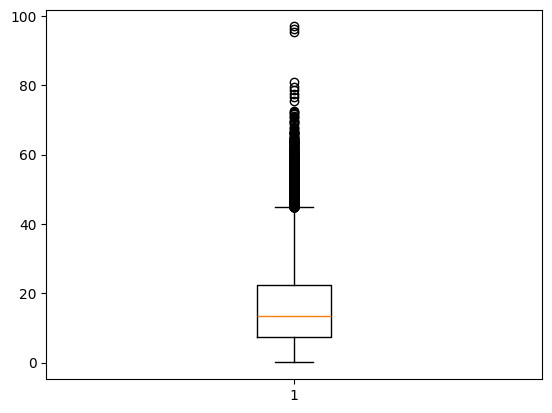

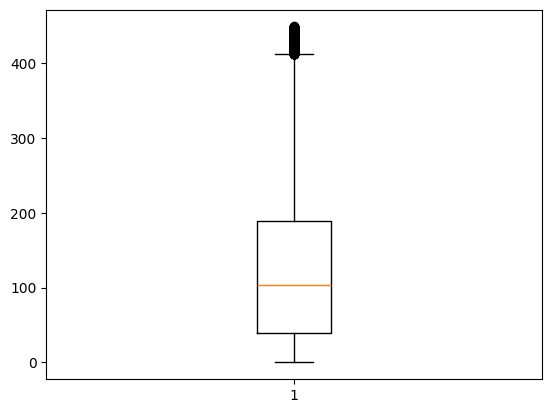

In [397]:
plt.boxplot(data['demand_value'])
plt.show()

plt.boxplot(data['calculated_duration_minutes'])
plt.show()

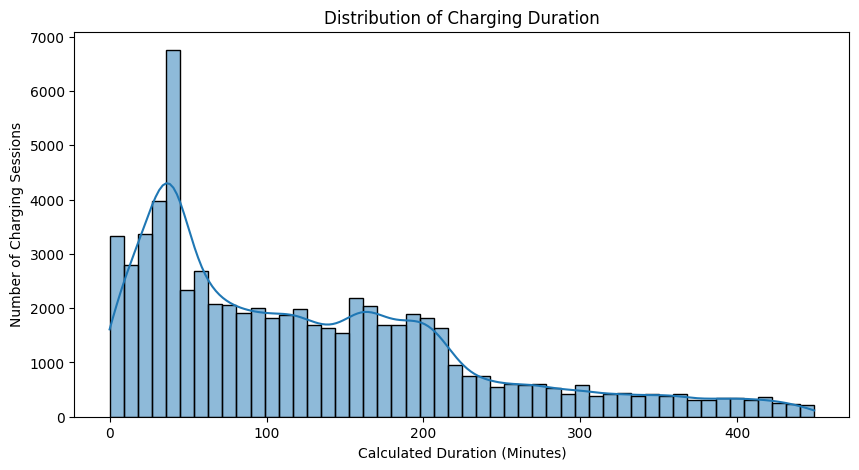

In [398]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x="calculated_duration_minutes",
    bins=50,
    kde=True
)

plt.title("Distribution of Charging Duration")
plt.xlabel("Calculated Duration (Minutes)")
plt.ylabel("Number of Charging Sessions")

plt.show()

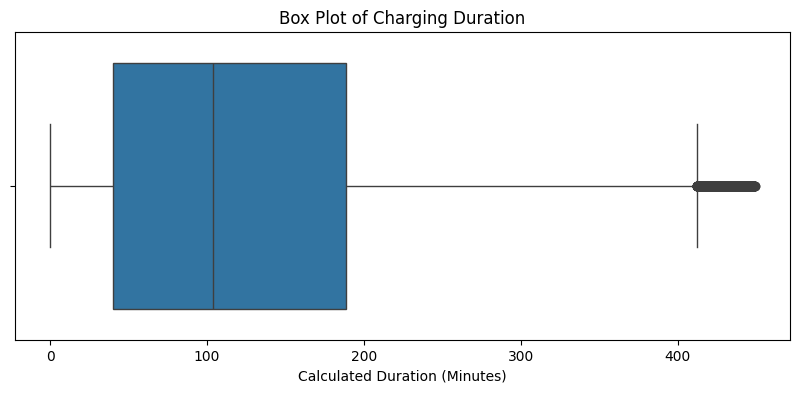

In [399]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=data["calculated_duration_minutes"]
)

plt.title("Box Plot of Charging Duration")
plt.xlabel("Calculated Duration (Minutes)")

plt.show()

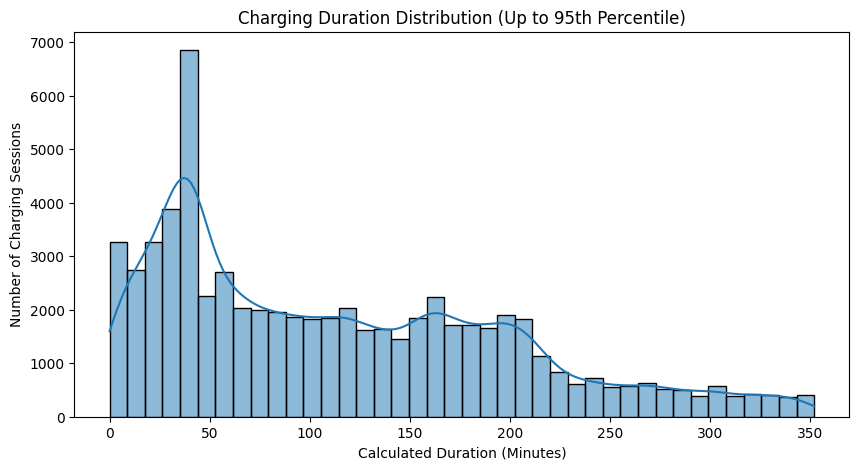

In [400]:
upper_limit = data["calculated_duration_minutes"].quantile(0.95)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=data[
        data["calculated_duration_minutes"] <= upper_limit
    ],
    x="calculated_duration_minutes",
    bins=40,
    kde=True
)

plt.title("Charging Duration Distribution (Up to 95th Percentile)")
plt.xlabel("Calculated Duration (Minutes)")
plt.ylabel("Number of Charging Sessions")

plt.show()

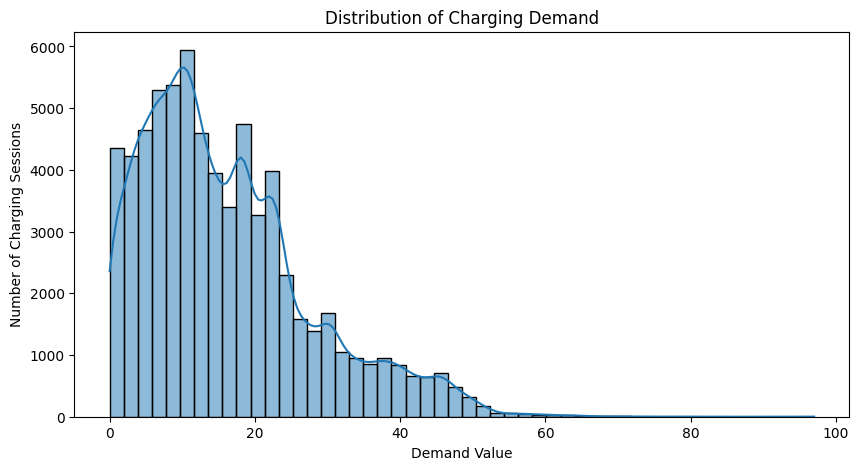

In [401]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data,
    x="demand_value",
    bins=50,
    kde=True
)

plt.title("Distribution of Charging Demand")
plt.xlabel("Demand Value")
plt.ylabel("Number of Charging Sessions")

plt.show()

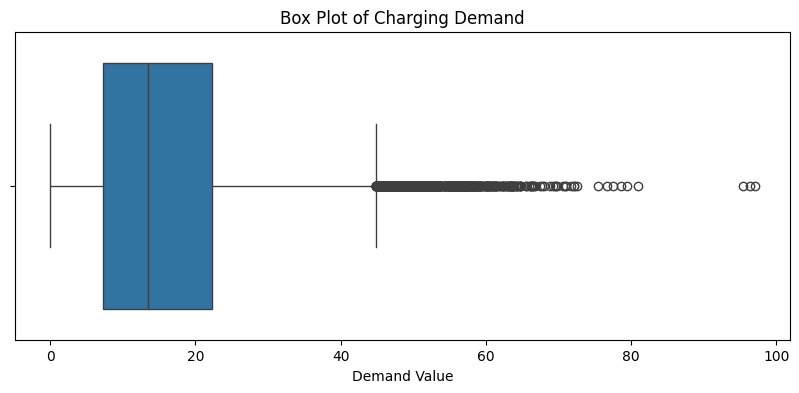

In [402]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=data["demand_value"]
)

plt.title("Box Plot of Charging Demand")
plt.xlabel("Demand Value")

plt.show()

In [403]:
data.columns

Index(['user_id', 'charger_id', 'charger_company_code', 'charging_location',
       'charger_type_code', 'start_day', 'start_time', 'end_day', 'end_time',
       'start_datetime', 'end_datetime', 'duration_minutes', 'demand_value',
       'start_hour', 'demand_level', 'calculated_duration_minutes',
       'charger_speed_category', 'time_taken_for_charging', 'charging_days',
       'charging_time', 'charging_hours', 'charging_minutes',
       'charger_company_name', 'duration_difference'],
      dtype='object')

In [404]:
start_time_parsed = pd.to_datetime(
    data['start_time'].astype(str).str[-8:],
    format='%H:%M:%S',
    errors='coerce'
)
data['start_hour']=start_time_parsed.dt.hour

hourly_summary = (
    data.groupby('start_hour')
    .agg(
        Total_Energy_kWh=('demand_value', 'sum'),
        Charging_Sessions=('demand_value', 'count')
    )
    .reset_index()
)

hourly_summary = hourly_summary.sort_values(
    'Total_Energy_kWh', ascending=False
)

print(hourly_summary.head(10))

    start_hour  Total_Energy_kWh  Charging_Sessions
18          18         100426.93               6027
17          17          94395.49               5986
19          19          90150.04               5017
20          20          79695.84               4208
16          16          72021.12               4934
21          21          71497.22               3535
8            8          66696.32               3998
15          15          54796.21               4096
9            9          54694.07               3934
14          14          52126.18               3813


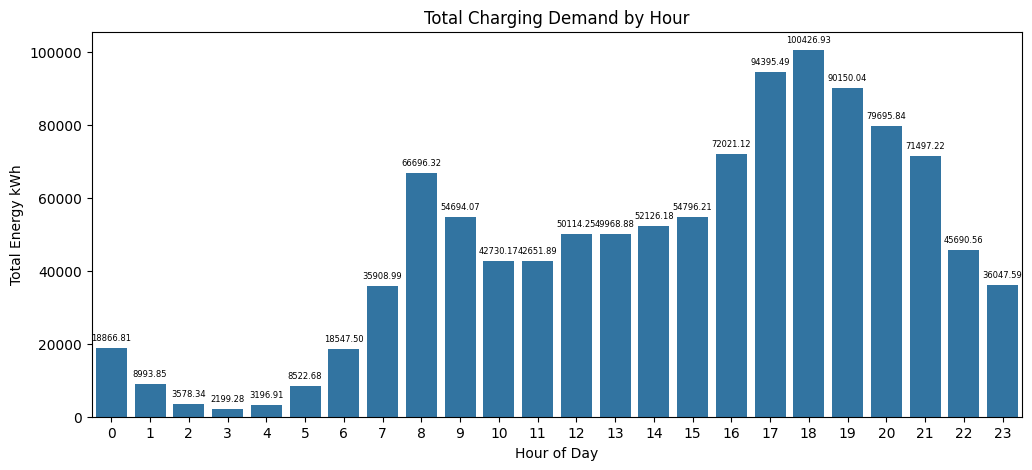

In [405]:
plt.figure(figsize=(12, 5))

ax=sns.barplot(
    data=hourly_summary.sort_values("start_hour"),
    x="start_hour",
    y="Total_Energy_kWh"

)
# Display values above every bar
ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=4,
    fontsize=6

)

plt.title("Total Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Total Energy kWh")

plt.xticks(range(24))
plt.show()

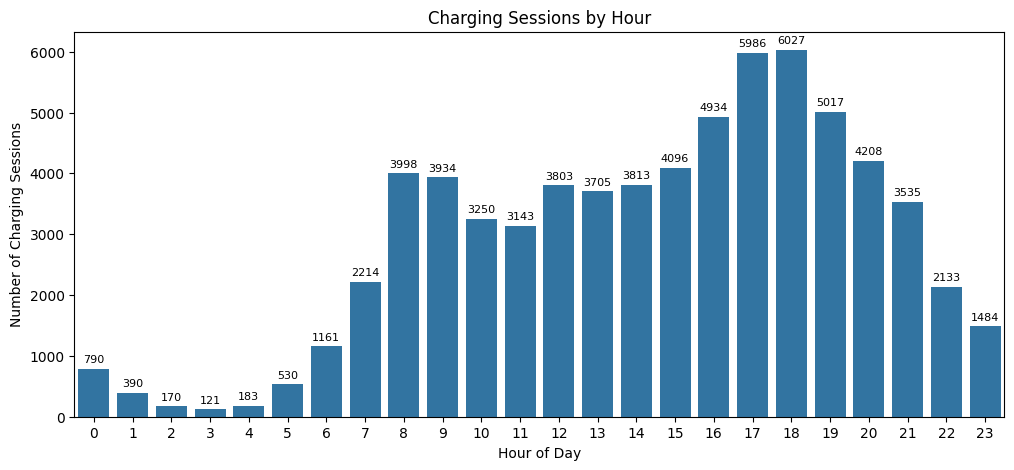

In [406]:
plt.figure(figsize=(12, 5))

ax=sns.barplot(
    data=hourly_summary.sort_values("start_hour"),
    x="start_hour",
    y="Charging_Sessions"

)
ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3,
    fontsize=8
)
plt.title("Charging Sessions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Charging Sessions")
plt.xticks(range(24))

plt.show()

In [407]:
hourly_summary["Average_Demand_Per_Session"] = (
    hourly_summary["Total_Energy_kWh"]
    / hourly_summary["Charging_Sessions"]
)

display(
    hourly_summary[
        [
            "start_hour",
            "Charging_Sessions",
            "Total_Energy_kWh",
            "Average_Demand_Per_Session"
        ]
    ].sort_values("start_hour")
)

,start_hour,Charging_Sessions,Total_Energy_kWh,Average_Demand_Per_Session
0,0,790,18866.81,23.882038
1,1,390,8993.85,23.061154
2,2,170,3578.34,21.049059
3,3,121,2199.28,18.175868
4,4,183,3196.91,17.469454
5,5,530,8522.68,16.080528
6,6,1161,18547.50,15.975452
7,7,2214,35908.99,16.219056
8,8,3998,66696.32,16.682421
9,9,3934,54694.07,13.902916


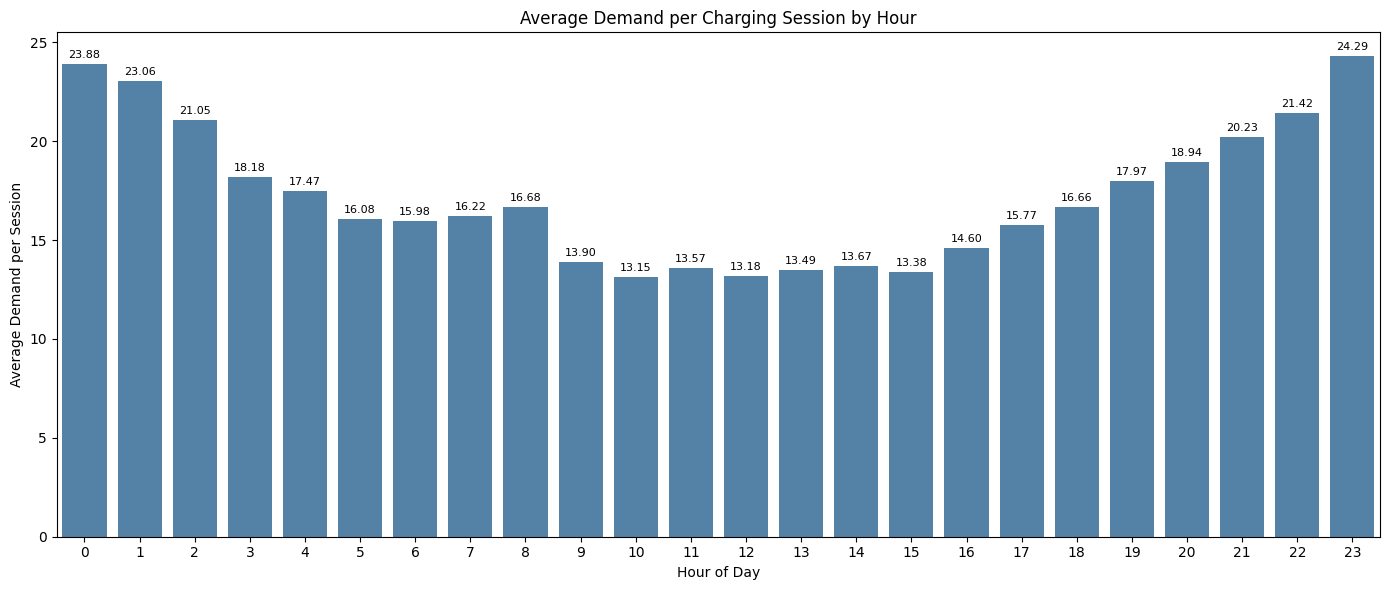

In [408]:
plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=hourly_summary.sort_values("start_hour"),
    x="start_hour",
    y="Average_Demand_Per_Session",
    color="steelblue"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3,
    fontsize=8
)

plt.title("Average Demand per Charging Session by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand per Session")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

Categorical EDA

In [409]:
data.columns

Index(['user_id', 'charger_id', 'charger_company_code', 'charging_location',
       'charger_type_code', 'start_day', 'start_time', 'end_day', 'end_time',
       'start_datetime', 'end_datetime', 'duration_minutes', 'demand_value',
       'start_hour', 'demand_level', 'calculated_duration_minutes',
       'charger_speed_category', 'time_taken_for_charging', 'charging_days',
       'charging_time', 'charging_hours', 'charging_minutes',
       'charger_company_name', 'duration_difference'],
      dtype='object')

In [410]:
company_summary = (
    data.groupby("charger_company_name")
    .agg(
        Charging_Sessions=("charger_company_name", "size"),
        Average_Demand=("demand_value", "mean")
    )
    .reset_index()
    .sort_values("Charging_Sessions", ascending=False)
)

display(company_summary)

,charger_company_name,Charging_Sessions,Average_Demand
1,Company B,42489,16.115544
0,Company A,26136,16.023253


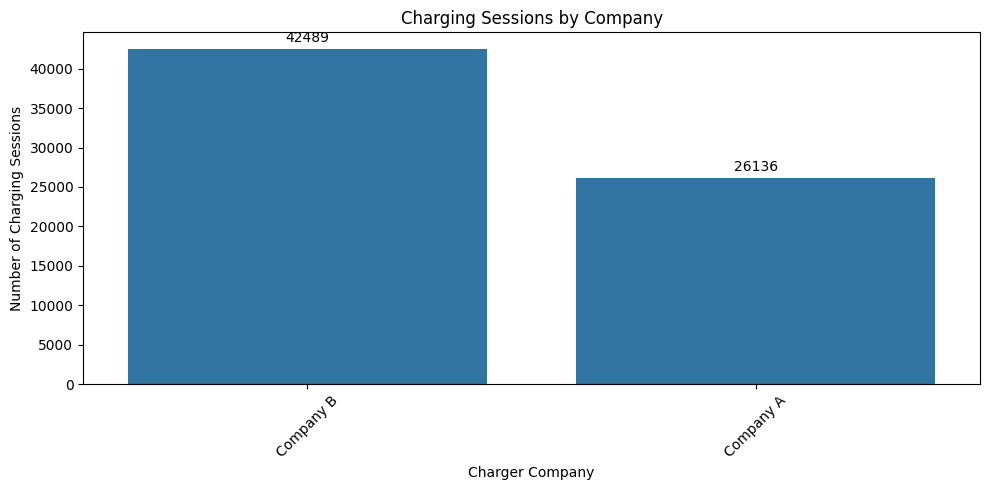

In [411]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=company_summary,
    x="charger_company_name",
    y="Charging_Sessions"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3
)

plt.title("Charging Sessions by Company")
plt.xlabel("Charger Company")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [412]:
speed_summary = (
    data.groupby("charger_speed_category")
    .agg(
        Charging_Sessions=("charger_speed_category", "size"),
        Average_Demand=("demand_value", "mean")
    )
    .reset_index()
    .sort_values("Charging_Sessions", ascending=False)
)

display(speed_summary)

,charger_speed_category,Charging_Sessions,Average_Demand
1,SlowCharger,53700,15.283861
0,FastCharger,14925,18.946318


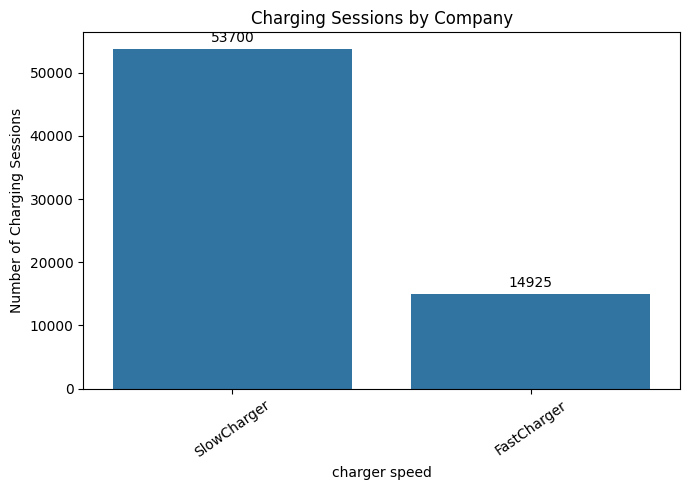

In [413]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=speed_summary,
    x="charger_speed_category",
    y="Charging_Sessions"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3
)

plt.title("Charging Sessions by Company")
plt.xlabel("charger speed")
plt.ylabel("Number of Charging Sessions")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [414]:
location_summary = (
    data.groupby("charging_location")
    .agg(
        Charging_Sessions=("charging_location", "size"),
        Average_Demand=("demand_value", "mean")
    )
    .reset_index()
    .sort_values("Charging_Sessions", ascending=False)
)

display(location_summary)

,charging_location,Charging_Sessions,Average_Demand
8,public area,13404,16.360416
1,apartment,12528,17.090721
11,resort,8293,15.796355
6,hotel,8277,13.953420
4,company,7255,15.264460
9,public institution,6695,16.126654
10,public parking lot,3352,16.802601
7,market,2885,15.467969
12,restaurant,2090,15.910445
3,camping,1441,21.582693


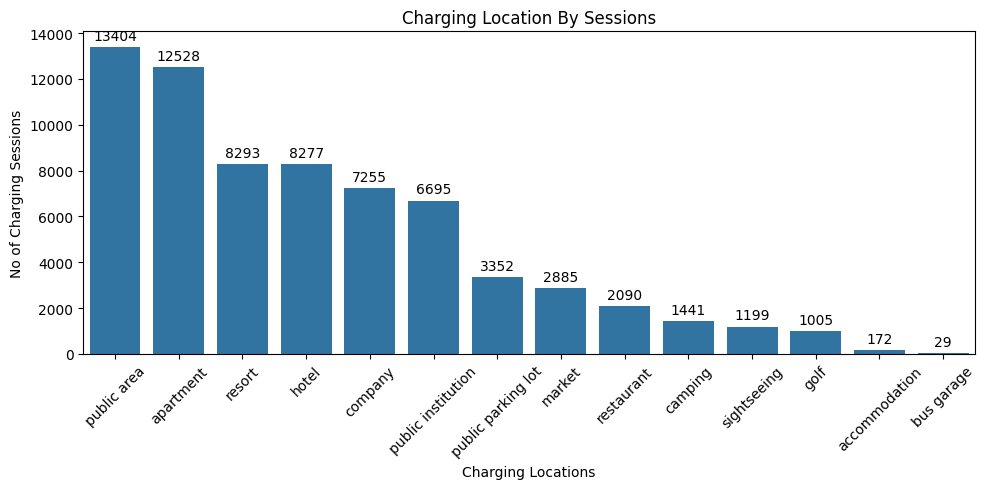

In [415]:
plt.figure(figsize=(10,5))
ax=sns.barplot(
    data=location_summary,
    x='charging_location',
    y='Charging_Sessions'
)

ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3

)

plt.title("Charging Location By Sessions")
plt.xlabel("Charging Locations")
plt.ylabel("No of Charging Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [416]:
demand_summary=(data.groupby('demand_level')
                .agg(Charging_Sessions=("demand_level", "size"),
                     Average_Demand=("demand_value", "mean")
                     )
                     .reset_index()
                     .sort_values("Charging_Sessions", ascending=False)
                )

display(demand_summary)

,demand_level,Charging_Sessions,Average_Demand
2,Medium Demand,24177,14.461003
1,Low Demand,23607,5.029347
0,High Demand,20841,30.476736


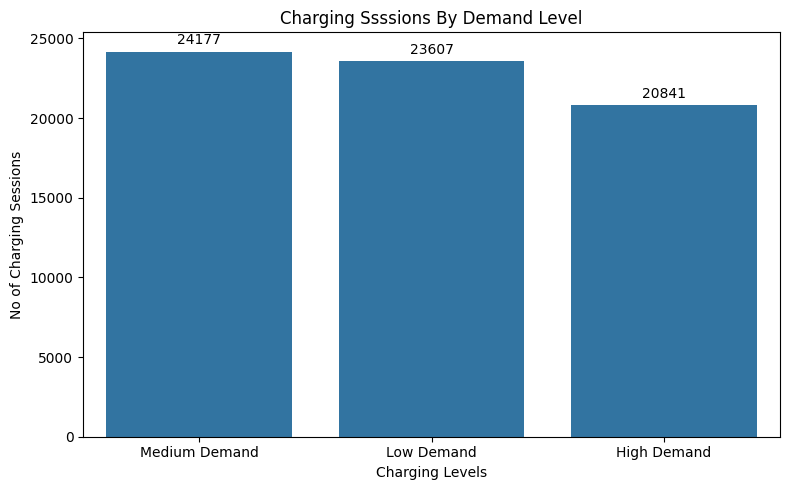

In [417]:
plt.figure(figsize=(8,5))
ax=sns.barplot(
    data=demand_summary,
    x='demand_level',
    y='Charging_Sessions'
)
ax.bar_label(
    ax.containers[0],
    fmt="%.0f",
    padding=3
)

plt.title('Charging Ssssions By Demand Level')
plt.xlabel('Charging Levels')
plt.ylabel('No of Charging Sessions')
plt.tight_layout()
plt.show()

,charger_company_name,charger_speed_category,Charging_Sessions,Average_Demand
0,Company A,FastCharger,14925,18.946318
1,Company A,SlowCharger,11211,12.131830
2,Company B,SlowCharger,42489,16.115544


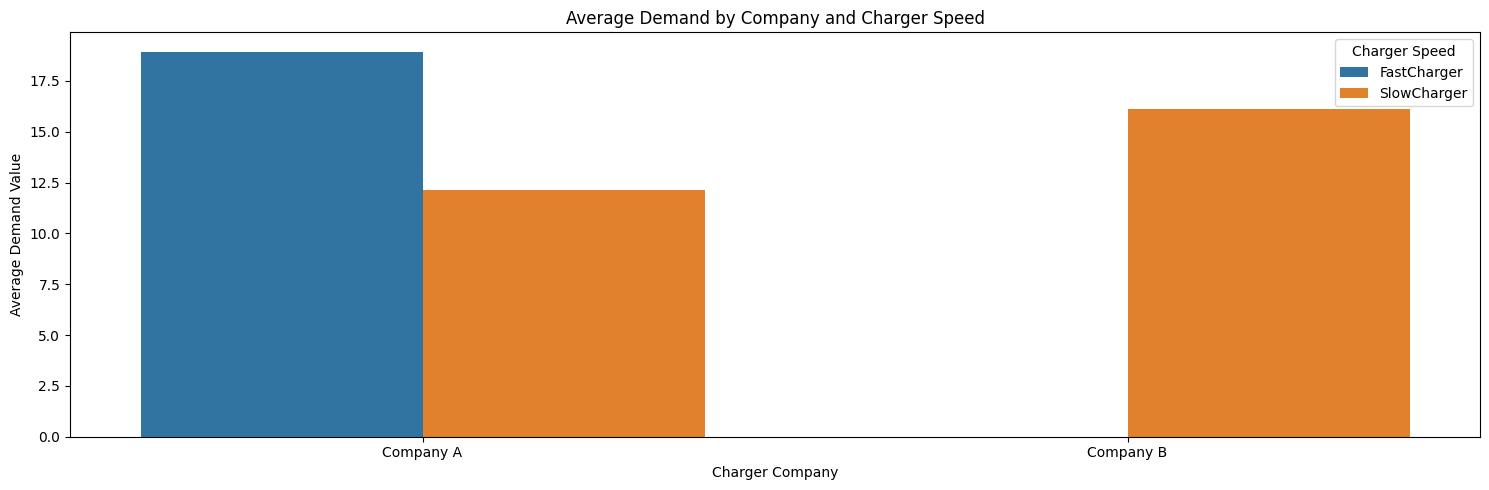

In [418]:
company_speed_summary = (
    data.groupby([
        "charger_company_name",
        "charger_speed_category"
    ])
    .agg(
        Charging_Sessions=("demand_value", "count"),
        Average_Demand=("demand_value", "mean")
    )
    .reset_index()
)

display(company_speed_summary)

plt.figure(figsize=(15, 5))

ax=sns.barplot(
    data=company_speed_summary,
    x="charger_company_name",
    y="Average_Demand",
    hue="charger_speed_category"
)

plt.title("Average Demand by Company and Charger Speed")
plt.xlabel("Charger Company")
plt.ylabel("Average Demand Value")
plt.legend(title="Charger Speed")
plt.tight_layout()
plt.show()



In [419]:
demand_speed_summary = pd.crosstab(
    data["charger_speed_category"],
    data["demand_level"]
)

display(demand_speed_summary)

demand_level,High Demand,Low Demand,Medium Demand
charger_speed_category,,,
FastCharger,5866,3458,5601
SlowCharger,14975,20149,18576


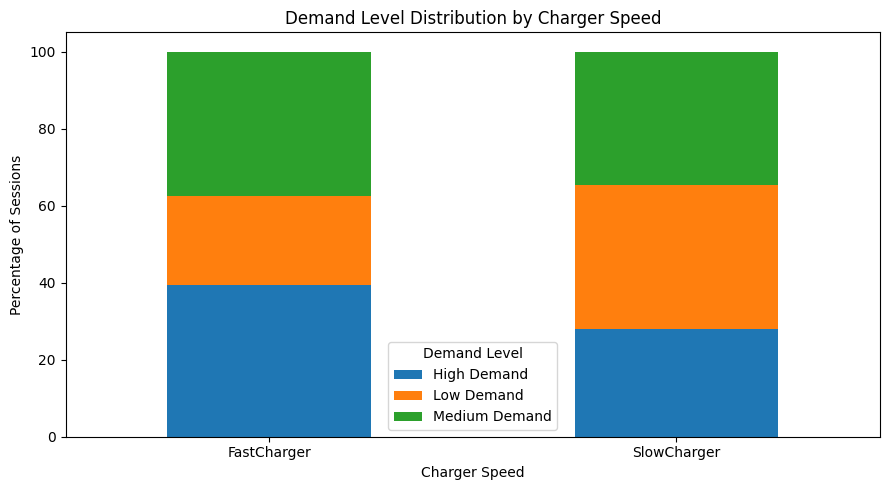

In [420]:
demand_speed_pct = pd.crosstab(
    data["charger_speed_category"],
    data["demand_level"],
    normalize="index"
) * 100

ax = demand_speed_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Demand Level Distribution by Charger Speed")
plt.xlabel("Charger Speed")
plt.ylabel("Percentage of Sessions")
plt.legend(title="Demand Level")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [421]:
location_demand = pd.crosstab(
    data["charging_location"],
    data["demand_level"]
)

display(location_demand)

demand_level,High Demand,Low Demand,Medium Demand
charging_location,,,
accommodation,130,18,24
apartment,4049,3906,4573
bus garage,18,4,7
camping,746,303,392
company,1911,2329,3015
golf,300,362,343
hotel,1952,3362,2963
market,855,1315,715
public area,4200,4623,4581


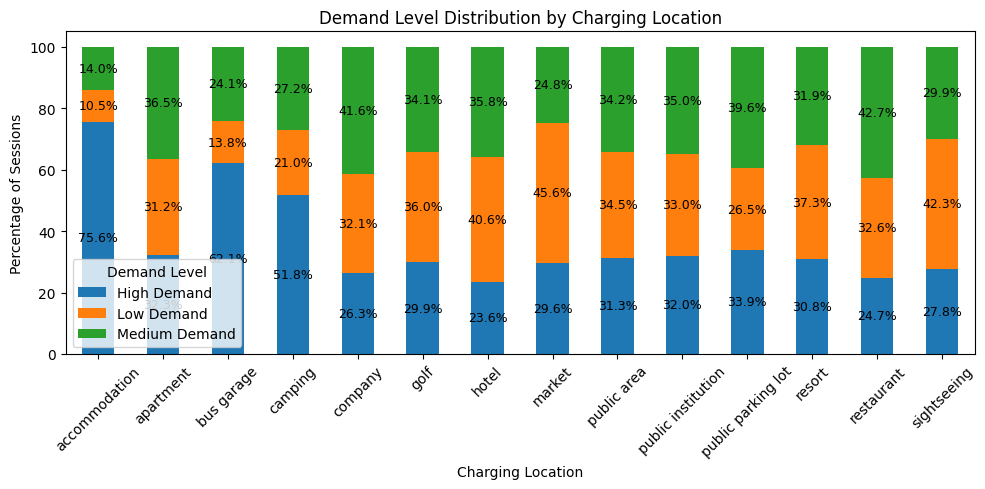

In [422]:
location_demand_pct = pd.crosstab(
    data["charging_location"],
    data["demand_level"],
    normalize="index"
) * 100

ax = location_demand_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 5 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9,
        color="black"
    )
plt.title("Demand Level Distribution by Charging Location")
plt.xlabel("Charging Location")
plt.ylabel("Percentage of Sessions")
plt.legend(title="Demand Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [423]:
duration_speed_summary = (
    data.groupby("charger_speed_category")
    .agg(
        Charging_Sessions=("calculated_duration_minutes", "count"),
        Average_Duration=("calculated_duration_minutes", "mean"),
        Median_Duration=("calculated_duration_minutes", "median")
    )
    .reset_index()
)

display(duration_speed_summary.round(2))

,charger_speed_category,Charging_Sessions,Average_Duration,Median_Duration
0,FastCharger,14925,35.82,36.13
1,SlowCharger,53700,153.75,140.15


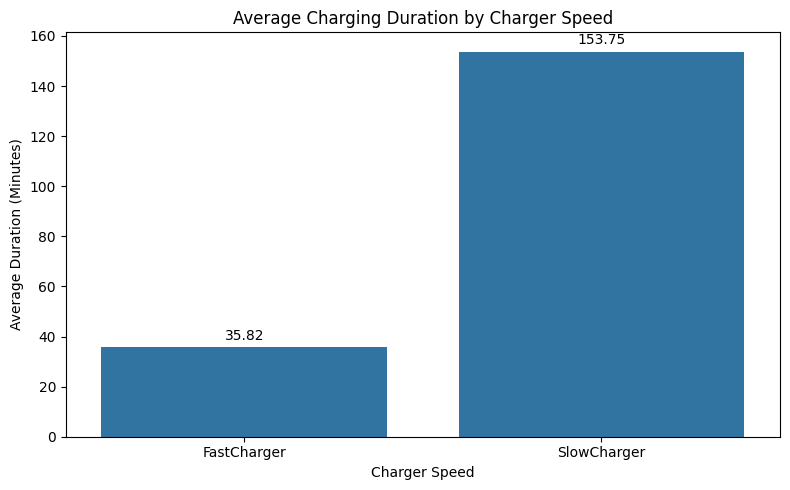

In [424]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=duration_speed_summary,
    x="charger_speed_category",
    y="Average_Duration"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3
)

plt.title("Average Charging Duration by Charger Speed")
plt.xlabel("Charger Speed")
plt.ylabel("Average Duration (Minutes)")
plt.tight_layout()
plt.show()

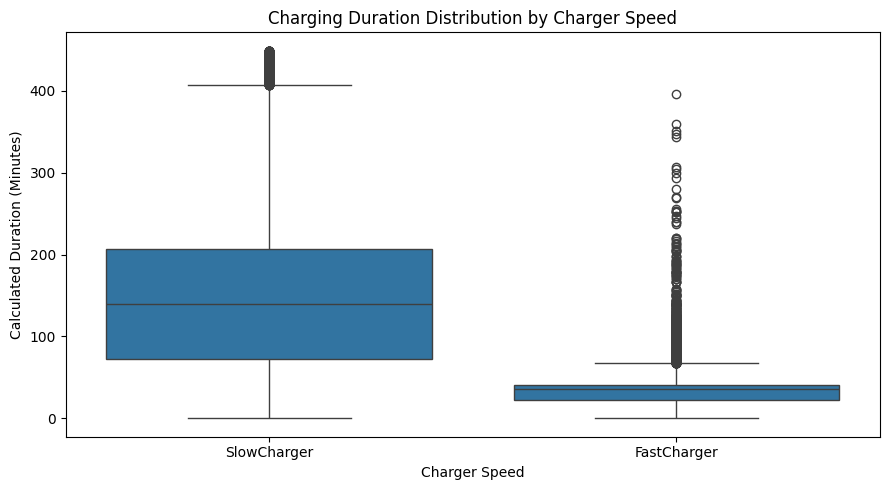

In [425]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="charger_speed_category",
    y="calculated_duration_minutes"
)

plt.title("Charging Duration Distribution by Charger Speed")
plt.xlabel("Charger Speed")
plt.ylabel("Calculated Duration (Minutes)")
plt.tight_layout()
plt.show()

Charging speed vs average demand

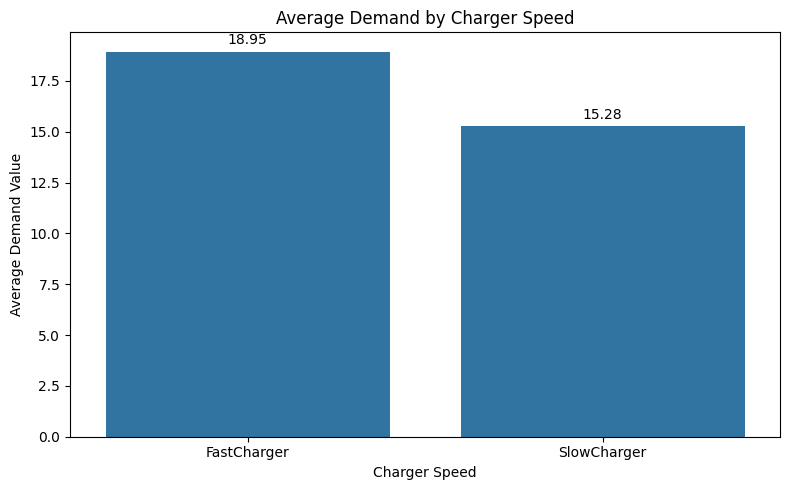

In [426]:
speed_demand = (
    data.groupby("charger_speed_category")
    .agg(
        Average_Demand=("demand_value", "mean"),
        Charging_Sessions=("demand_value", "count")
    )
    .reset_index()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=speed_demand,
    x="charger_speed_category",
    y="Average_Demand"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.title("Average Demand by Charger Speed")
plt.xlabel("Charger Speed")
plt.ylabel("Average Demand Value")
plt.tight_layout()
plt.show()

Charging location vs average demand

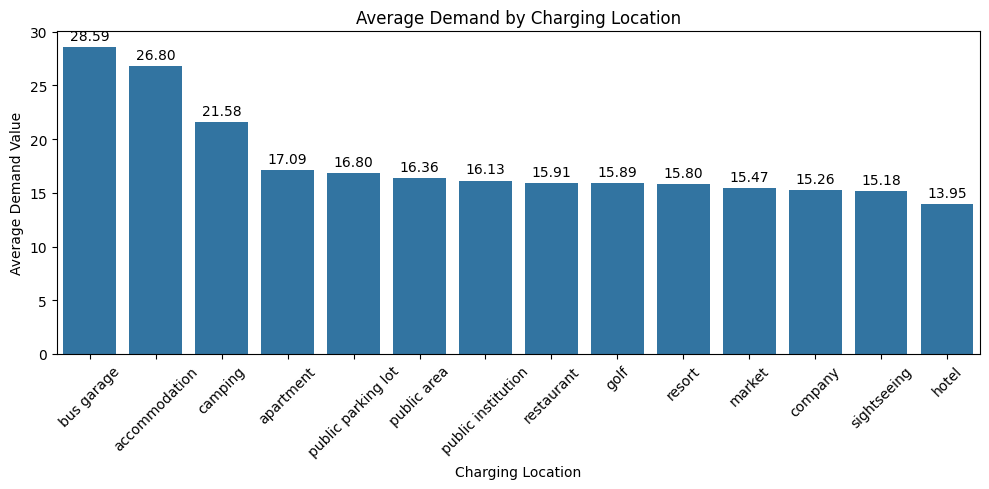

In [427]:
location_demand = (
    data.groupby("charging_location")
    .agg(
        Average_Demand=("demand_value", "mean"),
        Charging_Sessions=("demand_value", "count")
    )
    .reset_index()
    .sort_values("Average_Demand", ascending=False)
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=location_demand,
    x="charging_location",
    y="Average_Demand"
)

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.title("Average Demand by Charging Location")
plt.xlabel("Charging Location")
plt.ylabel("Average Demand Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Charging duration vs demand

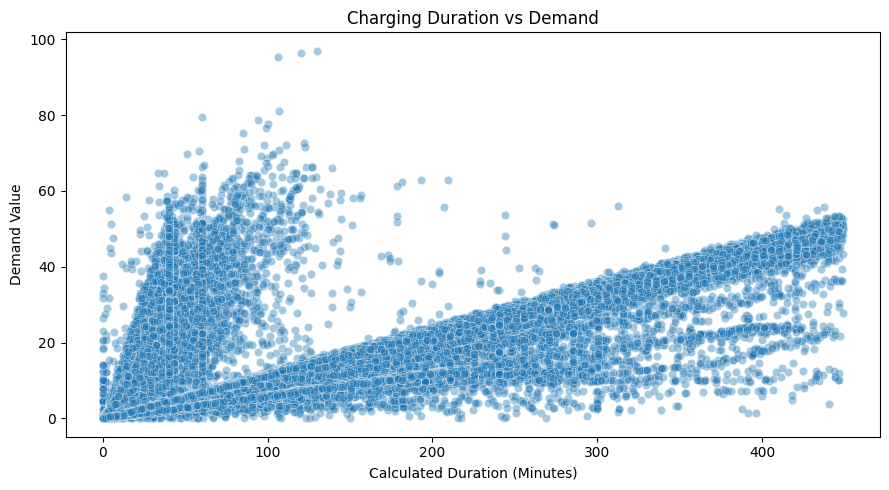

In [428]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=data,
    x="calculated_duration_minutes",
    y="demand_value",
    alpha=0.4
)

plt.title("Charging Duration vs Demand")
plt.xlabel("Calculated Duration (Minutes)")
plt.ylabel("Demand Value")
plt.tight_layout()
plt.show()

correlation

In [429]:
correlation = data[
    ["calculated_duration_minutes", "demand_value"]
].corr(method="pearson")

display(correlation)

print(
    "Pearson correlation:",
    round(
        data["calculated_duration_minutes"]
        .corr(data["demand_value"]),
        3
    )
)

,calculated_duration_minutes,demand_value
calculated_duration_minutes,1.000000,0.666419
demand_value,0.666419,1.000000


Pearson correlation: 0.666


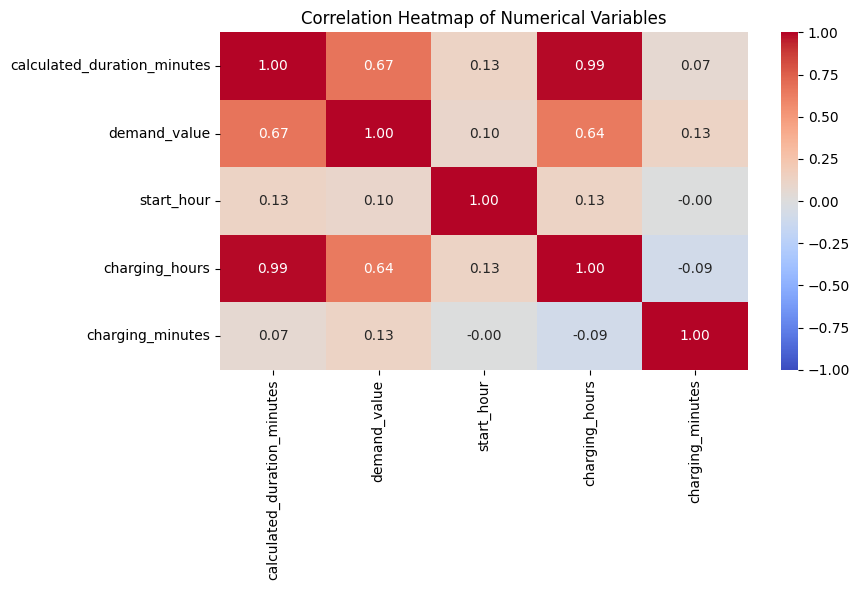

In [430]:
numeric_cols = [
    "calculated_duration_minutes",
    "demand_value",
    "start_hour",
    "charging_hours",
    "charging_minutes"
]

corr_matrix = data[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()